## Libraries

In [2]:
import tensorflow as tf
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Rescaling, Resizing, RandomFlip, RandomRotation
import os
import random
import numpy as np
from glob import glob
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

## Paths and Constants

In [3]:
path_train = r"../Data/dataset_yawn_eye/train"
path_test = r"../Data/dataset_yawn_eye/test/"
# labels_name = os.listdir(path_train)


## Preprocessing
Create and store tensorflow records for training and validation data

In [4]:
def label_2_bytes(val):
    if isinstance(val, type(tf.constant(0))): 
        val = val.numpy() 

    return tf.train.Feature(bytes_list = tf.train.BytesList(value = [val]))


def encode(img, label_encoded):
    feature = {
        'image' : tf.train.Feature(bytes_list = tf.train.BytesList(value = [img])),
        'label' : label_2_bytes(tf.io.serialize_tensor(label_encoded))
    }
    
    example = tf.train.Example(features = tf.train.Features(feature = feature))

    return example.SerializeToString()


def get_all_labels(path):
    labels = os.listdir(path)
    labels.remove(".DS_Store")

    return labels


def write_tf_record(record_path, files):
    labels = get_all_labels(path_train) # ['Closed','Open']

    with tf.io.TFRecordWriter(record_path, options = tf.io.TFRecordOptions(compression_type = "GZIP")) as writer:
        random.shuffle(files)

        for file in files:
            label_encoding = np.array([0, 0, 0, 0], dtype = 'float64')
            img = open(file, 'rb').read()
            current_label = file.split('/')[-2]
            current_label = labels.index(current_label)
            label_encoding[current_label] = 1.0 # one-hot-encoding
            tf_example = encode(img, label_encoding)

            writer.write(tf_example)


def get_combined_files(path):
    return glob(path + "/Closed/*") \
        + glob(path + "/Open/*") \
        + glob(path + "/no_yawn/*") \
        + glob(path + "/yawn/*")


def create_record_training(path):
    combined_files = get_combined_files(path)

    write_tf_record("../Data/tfrecords/training", combined_files)

    
def create_record_validation(path):
    combined_files = get_combined_files(path)

    write_tf_record("../Data/tfrecords/test", combined_files[ : len(combined_files) // 2])
    write_tf_record("../Data/tfrecords/validation", combined_files[len(combined_files) // 2 : ])
       

### Call methods to create tensorflow records

In [5]:
create_record_training(path_train)
create_record_validation(path_test)

### Create tensorflow dataset from records

In [6]:
def map_img_2_label(tf_example):
    feature = {
        "image" : tf.io.FixedLenFeature([], tf.string),
        "label" : tf.io.FixedLenFeature([], tf.string)
    }

    features = tf.io.parse_single_example(tf_example, feature)

    img = tf.io.decode_jpeg(features["image"], channels = 3)
    img = tf.image.resize(img, (256, 256))
    label = tf.io.parse_tensor(features["label"], out_type = tf.float64)
    label = tf.reshape(label, shape = (4, ))

    return img, label


def data_config(data: tf.data.TFRecordDataset, batch_size):
    data = data.map(map_img_2_label, tf.data.experimental.AUTOTUNE)
    data = data.shuffle(512)
    data = data.batch(batch_size, True)
    data = data.prefetch(tf.data.experimental.AUTOTUNE)

    return data


def read_dataset_from_tf_record(file, batch_size):
    read_data = tf.data.TFRecordDataset(file, "GZIP")
    dataset = data_config(read_data, batch_size)

    return dataset


def get_data_from_records(batch_size = 32):
    train_data = read_dataset_from_tf_record("../Data/tfrecords/training", batch_size)
    test_data = read_dataset_from_tf_record("../Data/tfrecords/test", batch_size)
    validation_data = read_dataset_from_tf_record("../Data/tfrecords/validation", batch_size)

    return train_data, test_data, validation_data

In [7]:
train_data, test_data, validation_data = get_data_from_records()

In [9]:
train_data.take(1)

<_TakeDataset element_spec=(TensorSpec(shape=(32, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(32, 4), dtype=tf.float64, name=None))>

In [7]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath = "../Data/models/cnn_model.h5", 
        monitor = "val_accuracy", 
        save_best_only = True, 
        mode = "max",
        verbose = 0
    )
]


## CNN Model

In [8]:
cnn_model = tf.keras.Sequential([
    Resizing(256, 256),
    Rescaling(1./255),
    RandomFlip(mode="horizontal"),
    RandomRotation(factor=0.4, fill_mode="reflect", interpolation="bilinear"),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(4, activation="softmax") # 4 output labels
])

cnn_model.compile(optimizer="adam", loss=tf.losses.CategoricalCrossentropy(), metrics=["accuracy"])


In [9]:
trained_model = cnn_model.fit(
    x = train_data, 
    epochs = 10, 
    callbacks = callback,
    validation_data = validation_data,
    verbose = 0
)


/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [10]:
cnn_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (32, 256, 256, 3)         0         
                                                                 
 rescaling (Rescaling)       (32, 256, 256, 3)         0         
                                                                 
 random_flip (RandomFlip)    (32, 256, 256, 3)         0         
                                                                 
 random_rotation (RandomRot  (32, 256, 256, 3)         0         
 ation)                                                          
                                                                 
 conv2d (Conv2D)             (32, 254, 254, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (32, 127, 127, 32)        0         
 D)                                                     

#### Evaluation of model

<Axes: >

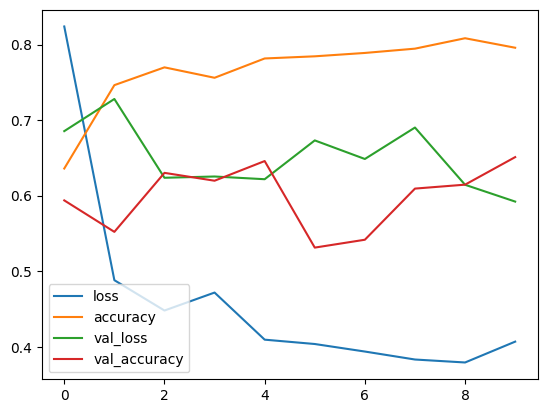

In [11]:
pd.DataFrame(trained_model.history).plot()

In [126]:
cnn_model.evaluate(validation_data)

3/3 [==============================] - 1s 243ms/step - loss: 0.0790 - accuracy: 0.9688


[0.07901684194803238, 0.96875]

In [127]:
cnn_model.evaluate(test_data)

3/3 [==============================] - 1s 216ms/step - loss: 0.3338 - accuracy: 0.8958


[0.3337614834308624, 0.8958333134651184]

In [128]:
cnn_model.save("../Data/models/eye_classifier.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
